In [1]:

from google.colab import files

uploaded = files.upload()


Saving bitcoin_price_data.csv to bitcoin_price_data.csv


In [2]:

import pandas as pd

df = pd.read_csv("bitcoin_price_data.csv")

print(df.head())
print(df.columns)
print(df.shape)


        Date       Open       High        Low      Close  percent_change_24h  \
0  26-Nov-20  18,729.84  18,866.29  16,351.03  17,150.62               -8.43   
1  25-Nov-20  19,104.41  19,390.97  18,581.15  18,732.12               -1.95   
2  24-Nov-20  18,365.01  19,348.27  18,128.66  19,107.46                4.04   
3  23-Nov-20  18,370.02  18,711.43  18,000.80  18,364.12               -0.03   
4  22-Nov-20  18,642.23  18,688.97  17,671.38  18,370.00               -1.46   

           Volume       Market Cap  
0  61,396,835,737  318,231,964,319  
1  43,710,357,371  347,558,803,507  
2  51,469,565,009  354,504,361,032  
3  42,741,112,308  340,698,070,308  
4  41,280,434,226  340,790,183,317  
Index(['Date', 'Open', 'High', 'Low', 'Close', 'percent_change_24h', 'Volume',
       'Market Cap'],
      dtype='object')
(2769, 8)


In [3]:

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Convert Date column into date format
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Convert Close column into numeric format
df['Close'] = pd.to_numeric(df['Close'], errors='coerce')

# Keep only required columns
df = df[['Date', 'Close']].copy()

# Sort data from oldest date to newest date
df = df.sort_values('Date')

# Handle missing closing prices
df['Close'] = df['Close'].interpolate()

# Remove remaining missing values
df = df.dropna(subset=['Date', 'Close'])

# Select 2000 consecutive records
df = df.tail(2000).reset_index(drop=True)

print("\nFirst 5 cleaned records:")
print(df.head())

print("\nTotal records:", len(df))
print("Missing values after cleaning:")
print(df.isnull().sum())


Missing values before cleaning:
Date                     0
Open                     0
High                     0
Low                      0
Close                    0
percent_change_24h    1769
Volume                   0
Market Cap               0
dtype: int64

First 5 cleaned records:
        Date   Close
0 2015-06-07  222.88
1 2015-06-08  228.49
2 2015-06-09  229.05
3 2015-06-10  228.80
4 2015-06-11  229.71

Total records: 2000
Missing values after cleaning:
Date     0
Close    0
dtype: int64


/tmp/ipykernel_967/746236174.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] = pd.to_datetime(df['Date'], errors='coerce')


In [4]:

from sklearn.preprocessing import MinMaxScaler

# Split index: 80% training, 20% testing
split_index = int(len(df) * 0.8)

# Fit scaler using training data only
scaler = MinMaxScaler(feature_range=(0, 1))

scaler.fit(df[['Close']].iloc[:split_index])

# Normalize all closing prices
scaled_close = scaler.transform(df[['Close']])

print("Original closing prices:")
print(df['Close'].head())

print("\nNormalized closing prices:")
print(scaled_close[:5])

print("\nTraining records:", split_index)
print("Testing records:", len(df) - split_index)


Original closing prices:
0    222.88
1    228.49
2    229.05
3    228.80
4    229.71
Name: Close, dtype: float64

Normalized closing prices:
[[0.01570959]
 [0.02282266]
 [0.02353269]
 [0.02321571]
 [0.02436952]]

Training records: 1600
Testing records: 400


In [7]:

# Step 5: Create sliding-window sequences

window_size = 7

X_train, y_train = [], []
X_test, y_test = [], []

# Training sequences
for i in range(window_size, split_index):
    X_train.append(scaled_close[i-window_size:i])
    y_train.append(scaled_close[i])

# Testing sequences
for i in range(split_index, len(scaled_close)):
    X_test.append(scaled_close[i-window_size:i])
    y_test.append(scaled_close[i])

# Convert lists into NumPy arrays
X_train = np.array(X_train)
y_train = np.array(y_train)

X_test = np.array(X_test)
y_test = np.array(y_test)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


X_train shape: (1593, 7, 1)
y_train shape: (1593, 1)
X_test shape: (400, 7, 1)
y_test shape: (400, 1)


In [8]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Create LSTM model
model = Sequential([
    LSTM(50, input_shape=(7, 1)),
    Dense(1)
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='mse'
)

# Display model architecture
model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:

history = model.fit(
    X_train,
    y_train,
    epochs=40,
    batch_size=16,
    validation_split=0.1,
    shuffle=False
)


Epoch 1/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0041 - val_loss: 6.6230e-05
Epoch 2/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0063 - val_loss: 5.9421e-06
Epoch 3/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0021 - val_loss: 2.1185e-07
Epoch 4/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 7.8185e-04 - val_loss: 5.7790e-07
Epoch 5/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 5.1849e-04 - val_loss: 1.2080e-06
Epoch 6/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.1936e-04 - val_loss: 5.2824e-08
Epoch 7/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.2813e-04 - val_loss: 1.8045e-06
Epoch 8/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.3727e-04 - val_loss: 3.7829e-06
Epoch 9/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.4030e-04 - val_loss: 4.6538e-06
Epoch 10/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 5.3814e-04 - val_loss: 4.6659e-06
Epoch 11/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 5.3329e-04 - val_loss: 4.3935e-0

In [10]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict using unseen test data
y_pred = model.predict(X_test)

# Convert normalized values back to actual prices
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))
y_pred_actual = scaler.inverse_transform(y_pred)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

print("\nActual closing prices:", y_test_actual[:5].flatten())
print("Predicted closing prices:", y_pred_actual[:5].flatten())


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
MAE: 1.73
RMSE: 1.73

Actual closing prices: [966.72 966.72 966.72 966.72 966.72]
Predicted closing prices: [968.4515 968.4515 968.4515 968.4515 968.4515]


In [11]:

print("First 10 test closing prices:")
print(df['Close'].iloc[split_index:split_index+10].to_list())

print("\nUnique test prices:", df['Close'].iloc[split_index:].nunique())

print("\nFirst 10 actual values:")
print(y_test_actual[:10].flatten())

print("\nFirst 10 predicted values:")
print(y_pred_actual[:10].flatten())


First 10 test closing prices:
[966.72, 966.72, 966.72, 966.72, 966.72, 966.72, 966.72, 966.72, 966.72, 966.72]

Unique test prices: 1

First 10 actual values:
[966.72 966.72 966.72 966.72 966.72 966.72 966.72 966.72 966.72 966.72]

First 10 predicted values:
[968.4515 968.4515 968.4515 968.4515 968.4515 968.4515 968.4515 968.4515
 968.4515 968.4515]


In [12]:

df_check = pd.read_csv("bitcoin_price_data.csv")

print("Total rows:", len(df_check))
print("\nFirst 10 closing prices:")
print(df_check['Close'].head(10).to_list())

print("\nLast 10 closing prices:")
print(df_check['Close'].tail(10).to_list())

print("\nUnique closing prices:", df_check['Close'].nunique())


Total rows: 2769

First 10 closing prices:
['17,150.62', '18,732.12', '19,107.46', '18,364.12', '18,370.00', '18,642.23', '18,621.31', '17,817.09', '17,804.01', '17,645.41']

Last 10 closing prices:
['113.57', '111.5', '112.3', '115.91', '112.5', '97.75', '105.21', '116.99', '139', '144.54']

Unique closing prices: 2738


Records: 2000
Unique closing prices: 1990
X_train: (1593, 7, 1)
X_test: (400, 7, 1)
Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0109 - val_loss: 0.0015
Epoch 2/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0130 - val_loss: 0.0047
Epoch 3/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0022 - val_loss: 0.0014
Epoch 4/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.9126e-04 - val_loss: 0.0020
Epoch 5/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.5058e-04 - val_loss: 0.0011
Epoch 6/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.0385e-04 - val_loss: 0.0012
Epoch 7/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2834e-04 - val_loss: 0.0012
Epoch 8/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3834e-04 - val_loss: 0.0012
Epoch 9/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6434e-04 - val_loss: 0.0013
Epoch 10/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9311e-04 - val_loss: 0.0013
Epoch 11/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2974e-04 - val_loss: 0.0014
Epoch 12/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step -

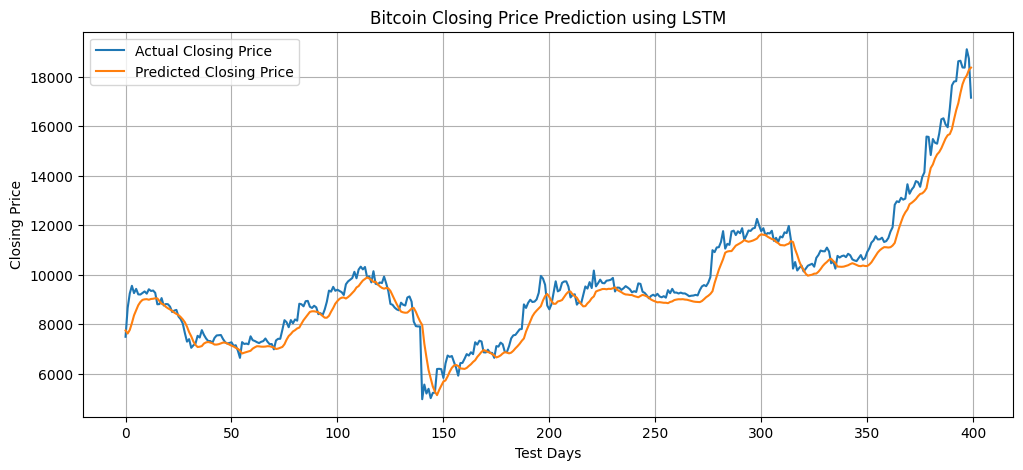

In [13]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# 1. Load and clean dataset
df = pd.read_csv("bitcoin_price_data.csv")
df['Close'] = pd.to_numeric(
    df['Close'].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
)
df['Date'] = pd.to_datetime(df['Date'], format='%d-%b-%y', errors='coerce')
df = df[['Date', 'Close']].dropna()
df = df.sort_values('Date').tail(2000).reset_index(drop=True)

print("Records:", len(df))
print("Unique closing prices:", df['Close'].nunique())

# 2. Chronological 80:20 split
split = int(len(df) * 0.8)

scaler = MinMaxScaler()
scaler.fit(df[['Close']].iloc[:split])
scaled = scaler.transform(df[['Close']])

# 3. Create 7-day sliding windows
X_train, y_train, X_test, y_test = [], [], [], []

for i in range(7, len(df)):
    if i < split:
        X_train.append(scaled[i-7:i])
        y_train.append(scaled[i])
    else:
        X_test.append(scaled[i-7:i])
        y_test.append(scaled[i])

X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

# 4. Build and train LSTM
model = Sequential([
    LSTM(50, input_shape=(7, 1)),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse')

history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

# 5. Predict unseen test data
pred = model.predict(X_test, verbose=0)

actual = scaler.inverse_transform(y_test)
predicted = scaler.inverse_transform(pred)

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("\nMAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("\nActual prices:", actual[:5].flatten())
print("Predicted prices:", predicted[:5].flatten())

# 6. Plot actual vs predicted prices
plt.figure(figsize=(12, 5))
plt.plot(actual, label='Actual Closing Price')
plt.plot(predicted, label='Predicted Closing Price')
plt.title('Bitcoin Closing Price Prediction using LSTM')
plt.xlabel('Test Days')
plt.ylabel('Closing Price')
plt.legend()
plt.grid(True)
plt.show()


In [14]:

# Predict Bitcoin closing prices for the next 30 days

last_7_days = scaled_close[-7:].reshape(1, 7, 1)

future_scaled = []
current_input = last_7_days.copy()

for _ in range(30):
    next_prediction = model.predict(current_input, verbose=0)
    future_scaled.append(next_prediction[0, 0])

    current_input = np.append(
        current_input[:, 1:, :],
        next_prediction.reshape(1, 1, 1),
        axis=1
    )

future_prices = scaler.inverse_transform(
    np.array(future_scaled).reshape(-1, 1)
)

print("Predicted Bitcoin closing prices for next 30 days:")
print(np.round(future_prices.flatten(), 2))


Predicted Bitcoin closing prices for next 30 days:
[18446.43 18386.94 18318.83 18244.28 18165.03 18082.03 17995.74 17906.35
 17824.09 17740.17 17655.18 17569.5  17483.33 17396.82 17310.06 17223.14
 17135.75 17047.94 16959.76 16871.22 16782.32 16693.06 16603.43 16513.43
 16423.06 16332.33 16241.24 16149.78 16057.97 15965.8 ]


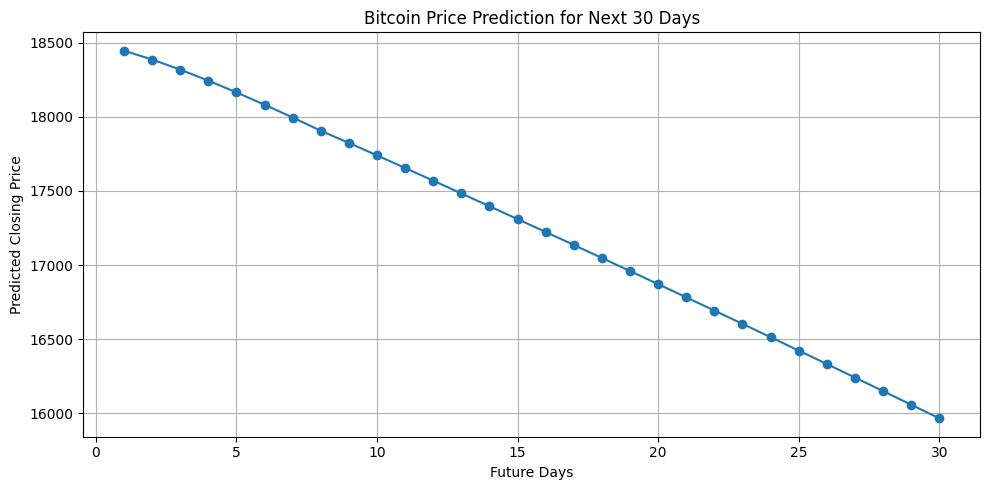

In [15]:

import matplotlib.pyplot as plt
import numpy as np

future_days = np.arange(1, 31)
predicted_prices = future_prices.flatten()

plt.figure(figsize=(10, 5))
plt.plot(future_days, predicted_prices, marker='o')

plt.title("Bitcoin Price Prediction for Next 30 Days")
plt.xlabel("Future Days")
plt.ylabel("Predicted Closing Price")
plt.grid(True)
plt.tight_layout()
plt.show()


In [6]:

import numpy as np
